# Task 1C – Điểm đặc trưng (interest points) và ghép cặp giữa hai ảnh

**FCVG101 – FruitSort Vision Assistant · Task 1: Core Image Analysis Engine**

Nội dung:

1. **Harris corner tự cài** (structure tensor + loại bỏ điểm không cực đại), kiểm chứng với `cv2.cornerHarris`.
2. So sánh **SIFT, ORB và Harris + descriptor SIFT** trên một cặp ảnh có **ground truth**. Ảnh thứ hai được tạo bằng một homography *biết trước* (xoay, co giãn, nghiêng phối cảnh, đổi độ sáng, thêm nhiễu), nên đếm được chính xác bao nhiêu cặp ghép **đúng**, thay vì chỉ nhìn bằng mắt.
3. **Ratio test của Lowe**: quét ngưỡng để chứng minh vì sao chọn 0.75.
4. Độ bền khi **xoay** và **đổi tỉ lệ**: phương pháp nào bất biến, phương pháp nào không.
5. **RANSAC homography** để kiểm chứng hình học, kèm thử với một **cặp ảnh không liên quan**.

Ảnh lấy từ dataset trái cây của Task 2. Các hàm nằm trong `src/features.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import features as ft
from src.filtering import load_image, to_gray

FRUIT = ROOT.parent / 'datasets' / 'fruits' / 'raw'
MAIN_IMG = FRUIT / 'orange' / 'kaggle_test_orange_77.jpg'      # nhiều chi tiết: lát cam, thớt gỗ
OTHER_IMG = FRUIT / 'banana' / 'kaggle_train_banana_10.jpg'    # ảnh KHÔNG liên quan
OUT = ROOT / 'results' / '1C'
OUT.mkdir(parents=True, exist_ok=True)
RATIO, TOL = 0.75, 3.0          # ngưỡng ratio test; sai số cho phép (px) để coi một cặp ghép là đúng

plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': 110})
pd.set_option('display.float_format', lambda v: f'{v:.4g}')

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches='tight')
    plt.show()

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img1 = load_image(MAIN_IMG, max_side=512)
g1 = to_gray(img1)
print('Ảnh:', MAIN_IMG.name, g1.shape[::-1], '| OpenCV', cv2.__version__, '| phương pháp:', ft.METHODS)

Ảnh: kaggle_test_orange_77.jpg (512, 384) | OpenCV 5.0.0 | phương pháp: ('SIFT', 'ORB', 'Harris+SIFT')


## 1. Harris corner – tự cài

Với gradient $I_x, I_y$ (Sobel), **structure tensor** tại mỗi pixel là
$M=\sum_{w} \begin{bmatrix} I_x^2 & I_xI_y\\ I_xI_y & I_y^2\end{bmatrix}$, lấy tổng có trọng số trong một cửa sổ $w$ (Gaussian hoặc box).

Độ đo góc: $R=\det M - k\,(\operatorname{tr} M)^2$, với $k \approx 0.04$–$0.06$. Cách đọc $R$:

- $R \gg 0$: **góc** (hai trị riêng của $M$ đều lớn).
- $R \ll 0$: **cạnh** (một trị riêng lớn).
- $|R|$ nhỏ: **vùng phẳng**.

Sau đó chọn điểm theo ngưỡng $R > \tau \cdot \max R$, và giữ **cực đại địa phương** (non-maximum suppression) trong cửa sổ 7×7.

**Kiểm chứng:** `cv2.cornerHarris` dùng cửa sổ box, nên chạy bản tự cài với `window='box'` để so sánh cùng điều kiện. Hai bản đồ $R$ chỉ khác nhau một hệ số tỉ lệ, do OpenCV chuẩn hoá Sobel khác. Vì vậy đo bằng **hệ số tương quan** và **mức trùng của các góc mạnh nhất**.

Tương quan R tự cài vs cv2.cornerHarris: 1.0000000000
200 góc mạnh nhất: 100.0% trùng vị trí (sai lệch <= 1 px)


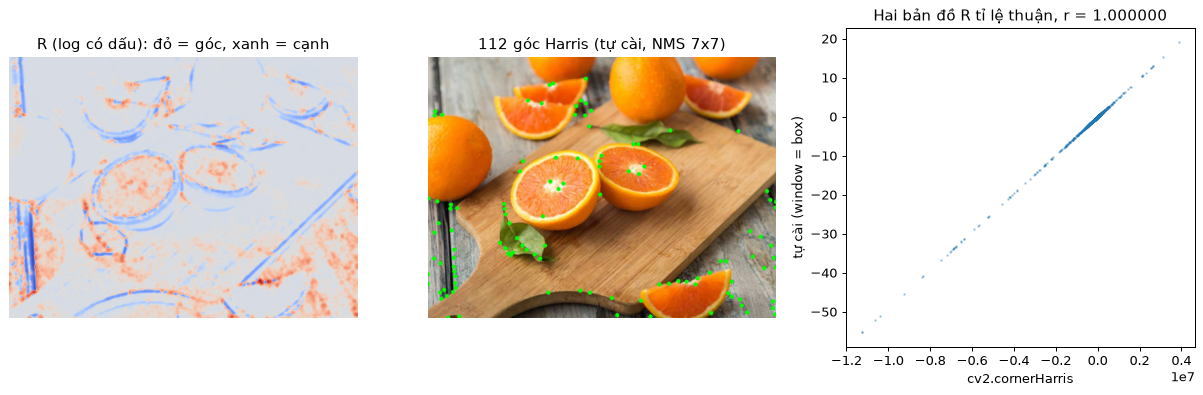

Số góc theo k và ngưỡng tương đối τ:


rel_threshold,0.001,0.01,0.05
k,,,
0.04,414,112,19
0.06,387,99,17
0.1,351,91,15


In [2]:
R_mine = ft.harris_response(g1, k=0.04, window='box', block_size=3)
R_cv = cv2.cornerHarris(g1.astype(np.float32), blockSize=3, ksize=3, k=0.04)
corr = np.corrcoef(R_mine.ravel(), R_cv.ravel())[0, 1]

def top_corners(R, n=200, nms=7):
    lm = cv2.dilate(R, np.ones((nms, nms), np.uint8))
    ys, xs = np.nonzero((R == lm) & (R > 0))
    o = np.argsort(R[ys, xs])[::-1][:n]
    return np.column_stack([xs[o], ys[o]])
a, b = top_corners(R_mine), top_corners(R_cv.astype(np.float64))
agree = np.mean(np.linalg.norm(a[:, None] - b[None], axis=2).min(axis=1) <= 1)
print(f'Tương quan R tự cài vs cv2.cornerHarris: {corr:.10f}')
print(f'200 góc mạnh nhất: {agree:.1%} trùng vị trí (sai lệch <= 1 px)')

R = ft.harris_response(g1, k=0.04, sigma=1.5)            # bản Harris cổ điển, cửa sổ Gaussian
pts = ft.harris_corners(g1, k=0.04, sigma=1.5, rel_threshold=0.01)
vis = img1.copy()
for x, y in pts:
    cv2.circle(vis, (int(x), int(y)), 3, (0, 255, 0), -1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].imshow(np.sign(R) * np.log1p(np.abs(R) * 1e4), cmap='coolwarm'); ax[0].set_title('R (log có dấu): đỏ = góc, xanh = cạnh'); ax[0].axis('off')
ax[1].imshow(rgb(vis)); ax[1].set_title(f'{len(pts)} góc Harris (tự cài, NMS 7x7)'); ax[1].axis('off')
ax[2].scatter(R_cv.ravel()[::7], R_mine.ravel()[::7], s=1, alpha=0.3); ax[2].set_xlabel('cv2.cornerHarris'); ax[2].set_ylabel('tự cài (window = box)')
ax[2].set_title(f'Hai bản đồ R tỉ lệ thuận, r = {corr:.6f}')
save(fig, 'harris_scratch.png')

sens = pd.DataFrame([dict(k=k, rel_threshold=t, n_corners=len(ft.harris_corners(g1, k=k, rel_threshold=t)))
                     for k in [0.04, 0.06, 0.10] for t in [0.001, 0.01, 0.05]]).pivot(index='k', columns='rel_threshold', values='n_corners')
print('Số góc theo k và ngưỡng tương đối τ:')
sens

## 2. Cặp ảnh có ground truth

Ảnh thứ hai là ảnh gốc biến đổi bởi homography $H_{true}$: xoay 25°, thu nhỏ 0.85, nghiêng phối cảnh, tăng sáng 20 mức, thêm nhiễu Gaussian σ = 5.

Một cặp ghép $(p_1, p_2)$ được coi là **đúng** khi $\lVert H_{true}\,p_1 - p_2\rVert < 3$ px. Các chỉ số:

- **precision** = số cặp đúng / số cặp qua ratio test.
- **repeatability** = tỉ lệ điểm ở ảnh 1 được phát hiện lại ở ảnh 2.
- **H_corner_error** = sai số trung bình (px) tại 4 góc ảnh giữa homography ước lượng bằng RANSAC và $H_{true}$.

In [3]:
img2, H_true = ft.synthetic_view(img1, angle=25, scale=0.85, perspective=0.3, brightness=20, noise_sigma=5, seed=0)
g2 = to_gray(img2)
res = {m: ft.evaluate_pair(g1, g2, m, H_true, RATIO, TOL) for m in ft.METHODS}
table = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith('_')} for r in res.values()]).set_index('method')
table.to_csv(OUT / 'method_comparison.csv')
print('H_true =\n', np.round(H_true, 4))
table

H_true =
 [[ 1.049600e+00  4.894000e-01 -5.937140e+01]
 [-3.229000e-01  9.606000e-01  1.257138e+02]
 [ 5.000000e-04  2.000000e-04  1.000000e+00]]


,kp1,kp2,good_matches,ransac_inliers,time_ms,correct_matches,precision,repeatability,H_corner_error_px
method,,,,,,,,,
SIFT,771,635,340,331,101.5,331,0.9735,0.6332,0.1978
ORB,1378,1535,543,531,490.3,521,0.9595,0.8394,1.294
Harris+SIFT,112,102,3,0,66.63,1,0.3333,0.7677,NaN


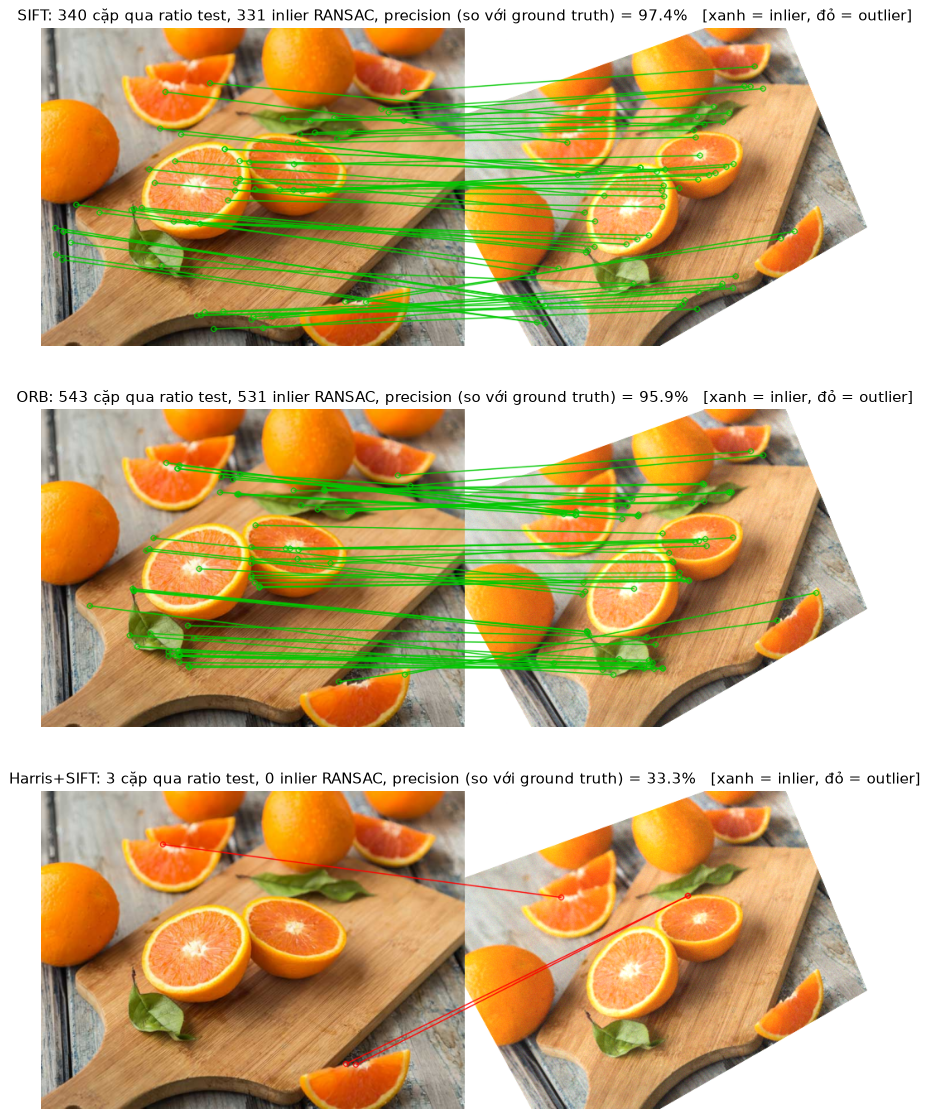

In [4]:
fig, ax = plt.subplots(len(ft.METHODS), 1, figsize=(14, 5.2 * len(ft.METHODS)))
for a, (m, r) in zip(ax, res.items()):
    canvas = ft.draw_matches(img1, r['_kp1'], img2, r['_kp2'], r['_good'], r['_inliers'], max_draw=60)
    a.imshow(rgb(canvas)); a.axis('off')
    a.set_title(f"{m}: {r['good_matches']} cặp qua ratio test, {r['ransac_inliers']} inlier RANSAC, "
                f"precision (so với ground truth) = {r['precision']:.1%}   [xanh = inlier, đỏ = outlier]")
save(fig, 'matches_methods.png')

**Vì sao Harris + SIFT thất bại ở đây dù tỉ lệ phát hiện lại điểm (repeatability) cao?**

Harris cho biết **vị trí** góc khá ổn định. Nhưng nó không có **hướng chính** và **kích thước** của điểm, nên descriptor được tính trên một mảnh ảnh cố định 16 px, không xoay theo ảnh. Khi ảnh xoay 25° và thu nhỏ, mảnh ảnh quanh cùng một góc trông khác hẳn, nên descriptor không khớp.

SIFT và ORB gán cho mỗi điểm một **hướng chính** (rotation invariant) và có **thang đo**, theo không gian thang đo với SIFT hoặc pyramid ảnh với ORB, nên vẫn ghép được.

## 3. Ratio test: chọn ngưỡng bằng dữ liệu

Với mỗi descriptor ở ảnh 1, tìm 2 láng giềng gần nhất ở ảnh 2. Chỉ giữ cặp nếu $d_1 < \rho\, d_2$: cặp tốt nhất phải **rõ ràng tốt hơn** cặp thứ hai, tức là không mơ hồ.

- $\rho$ nhỏ: ít cặp nhưng chính xác.
- $\rho$ lớn: nhiều cặp nhưng lẫn nhiều cặp sai.

Quét $\rho$ từ 0.5 đến 0.95 và đo trên ground truth.

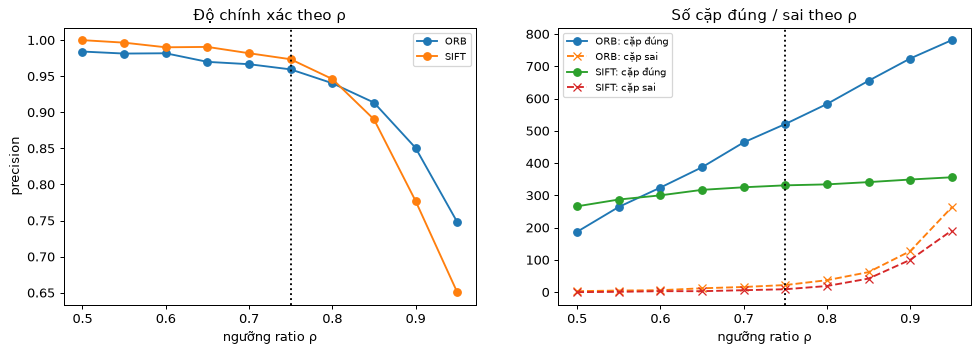

method,ORB,SIFT
ratio,,
0.5,0.9842,1
0.55,0.9814,0.9965
0.6,0.9818,0.9901
0.65,0.9699,0.9906
0.7,0.9667,0.9819
0.75,0.9595,0.9735
0.8,0.9403,0.9462
0.85,0.9135,0.8903
0.9,0.8508,0.7773


In [5]:
sweep = []
for m in ['SIFT', 'ORB']:
    kp1, d1 = ft.detect_and_describe(g1, m); kp2, d2 = ft.detect_and_describe(g2, m)
    for rho in np.round(np.arange(0.5, 0.96, 0.05), 2):
        good = ft.ratio_test_matches(d1, d2, ft.norm_for(m), rho)
        ok = ft.correct_matches(kp1, kp2, good, H_true, TOL)
        sweep.append(dict(method=m, ratio=rho, good=len(good), correct=int(ok.sum()), precision=ok.mean() if len(ok) else 0))
sweep = pd.DataFrame(sweep)
sweep.to_csv(OUT / 'ratio_sweep.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m, s in sweep.groupby('method'):
    ax[0].plot(s.ratio, s.precision, 'o-', label=m); ax[1].plot(s.ratio, s.correct, 'o-', label=f'{m}: cặp đúng')
    ax[1].plot(s.ratio, s.good - s.correct, 'x--', label=f'{m}: cặp sai')
for a in ax:
    a.axvline(RATIO, color='k', ls=':'); a.set_xlabel('ngưỡng ratio ρ'); a.legend(fontsize=8)
ax[0].set_ylabel('precision'); ax[0].set_title('Độ chính xác theo ρ'); ax[1].set_title('Số cặp đúng / sai theo ρ')
save(fig, 'ratio_sweep.png')
sweep.pivot(index='ratio', columns='method', values='precision')

## 4. Độ bền khi xoay và đổi tỉ lệ

Tạo ảnh thứ hai chỉ xoay (0° → 180°) hoặc chỉ co giãn (×0.4 → ×1.6), mỗi lần có $H_{true}$ tương ứng, rồi đếm **số cặp ghép đúng** của mỗi phương pháp.

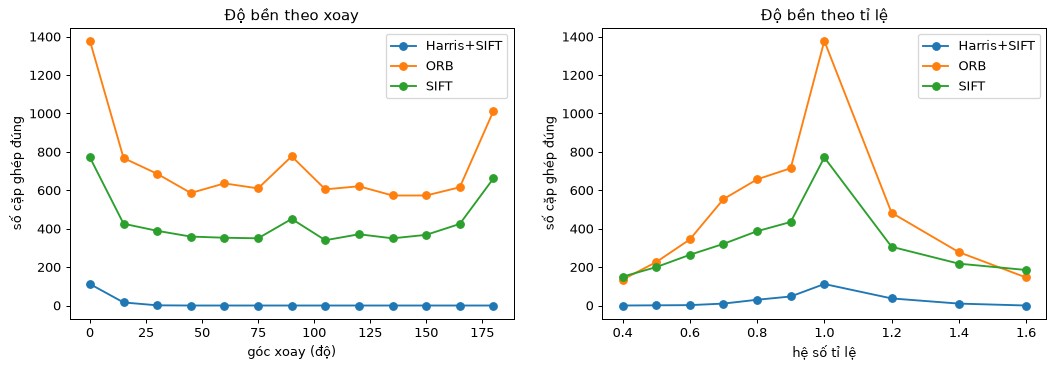

method       Harris+SIFT  ORB  SIFT
test  value                        
tỉ lệ 0.4              0  135   150
      0.5              1  226   200
      0.6              2  344   264
      0.7             10  554   321
      0.8             30  657   387
      0.9             47  715   435
      1              112 1378   771
      1.2             37  483   306
      1.4             10  278   218
      1.6              0  146   185
xoay  0              112 1378   771
      15              16  768   426
      30               1  686   389
      45               0  586   359
      60               0  636   353
      75               0  610   350
      90               0  777   451
      105              0  605   340
      120              0  621   371
      135              0  573   350
      150              0  573   368
      165              0  616   425
      180              0 1013   662

In [6]:
rob = []
for ang in range(0, 181, 15):
    v, H = ft.synthetic_view(img1, angle=ang, scale=1.0)
    for m in ft.METHODS:
        r = ft.evaluate_pair(g1, to_gray(v), m, H, RATIO, TOL)
        rob.append(dict(test='xoay', value=ang, method=m, correct=r['correct_matches'], precision=r['precision']))
for sc in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.4, 1.6]:
    v, H = ft.synthetic_view(img1, angle=0, scale=sc)
    for m in ft.METHODS:
        r = ft.evaluate_pair(g1, to_gray(v), m, H, RATIO, TOL)
        rob.append(dict(test='tỉ lệ', value=sc, method=m, correct=r['correct_matches'], precision=r['precision']))
rob = pd.DataFrame(rob)
rob.to_csv(OUT / 'robustness.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, (t, xl) in zip(ax, [('xoay', 'góc xoay (độ)'), ('tỉ lệ', 'hệ số tỉ lệ')]):
    for m, s in rob[rob.test == t].groupby('method'):
        a.plot(s.value, s.correct, 'o-', label=m)
    a.set_xlabel(xl); a.set_ylabel('số cặp ghép đúng'); a.set_title(f'Độ bền theo {t}'); a.legend()
save(fig, 'robustness.png')
rob.pivot_table(index=['test', 'value'], columns='method', values='correct')

## 5. RANSAC và cặp ảnh không liên quan

Ratio test vẫn để lọt một số cặp sai. **RANSAC** lặp lại nhiều lần: chọn ngẫu nhiên 4 cặp, tính homography, rồi đếm số cặp khớp với homography đó (**inlier**). Homography có nhiều inlier nhất được giữ lại.

- **Cùng cảnh:** nhiều inlier, tỉ lệ inlier cao, và homography ước lượng gần với $H_{true}$.
- **Hai ảnh không liên quan** (cam và chuối): vài cặp vẫn qua được ratio test do trùng hợp, nhưng RANSAC chỉ tìm được rất ít inlier.

Từ đó rút ra một **luật quyết định** đơn giản: hai ảnh được coi là cùng một cảnh khi có ít nhất 15 inlier và tỉ lệ inlier từ 50 % trở lên.

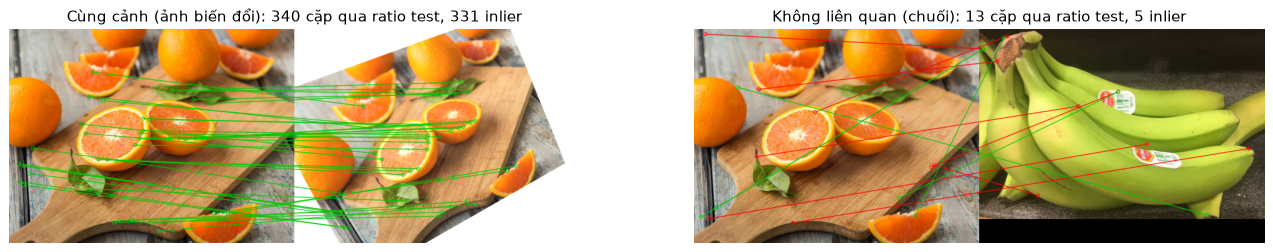

,good_matches,ransac_inliers,inlier_ratio,decision
pair,,,,
Cùng cảnh (ảnh biến đổi),340,331,0.9735,CÙNG CẢNH
Không liên quan (chuối),13,5,0.3846,KHÁC CẢNH


In [7]:
img3 = load_image(OTHER_IMG, max_side=512)
g3 = to_gray(img3)
pairs = {'Cùng cảnh (ảnh biến đổi)': (img2, g2), 'Không liên quan (chuối)': (img3, g3)}
dec_rows, draws = [], {}
for name, (im, g) in pairs.items():
    r = ft.evaluate_pair(g1, g, 'SIFT', None, RATIO)
    inl_ratio = r['ransac_inliers'] / max(r['good_matches'], 1)
    same = r['ransac_inliers'] >= 15 and inl_ratio >= 0.5
    dec_rows.append(dict(pair=name, good_matches=r['good_matches'], ransac_inliers=r['ransac_inliers'],
                         inlier_ratio=inl_ratio, decision='CÙNG CẢNH' if same else 'KHÁC CẢNH'))
    draws[name] = (im, r)
dec = pd.DataFrame(dec_rows).set_index('pair')
dec.to_csv(OUT / 'same_scene_decision.csv')

fig, ax = plt.subplots(1, 2, figsize=(18, 4.6))
for a, (name, (im, r)) in zip(ax, draws.items()):
    a.imshow(rgb(ft.draw_matches(img1, r['_kp1'], im, r['_kp2'], r['_good'], r['_inliers'], 40))); a.axis('off')
    a.set_title(f"{name}: {r['good_matches']} cặp qua ratio test, {r['ransac_inliers']} inlier")
save(fig, 'related_vs_unrelated.png')
dec

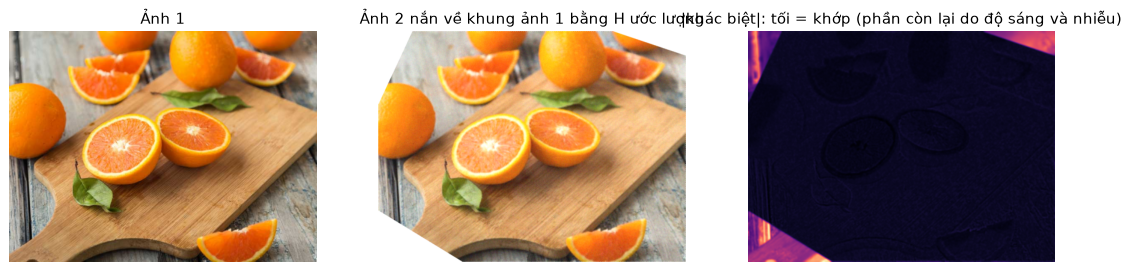

Sai số góc ảnh của H ước lượng so với H_true: 0.198 px


In [8]:
# Dùng homography RANSAC ước lượng (SIFT) để "nắn" ảnh 2 về khung ảnh 1 và so sánh
H_est = res['SIFT']['_H']
back = cv2.warpPerspective(img2, np.linalg.inv(H_est), (img1.shape[1], img1.shape[0]), borderValue=(255, 255, 255))
diff = cv2.absdiff(cv2.GaussianBlur(g1, (5, 5), 0), cv2.GaussianBlur(to_gray(back), (5, 5), 0))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(rgb(img1)); ax[0].set_title('Ảnh 1'); ax[0].axis('off')
ax[1].imshow(rgb(back)); ax[1].set_title('Ảnh 2 nắn về khung ảnh 1 bằng H ước lượng'); ax[1].axis('off')
ax[2].imshow(diff, cmap='magma'); ax[2].set_title('|khác biệt|: tối = khớp (phần còn lại do độ sáng và nhiễu)'); ax[2].axis('off')
save(fig, 'ransac_alignment.png')
print(f"Sai số góc ảnh của H ước lượng so với H_true: {table.loc['SIFT', 'H_corner_error_px']:.3f} px")

## 6. Lưu và tóm tắt

In [9]:
best = table.precision.idxmax()
fast = table.time_ms.idxmin()
rot_sift = rob[(rob.test == 'xoay') & (rob.method == 'SIFT')].correct.min()
rot_harris = rob[(rob.test == 'xoay') & (rob.method == 'Harris+SIFT') & (rob.value >= 30)].correct.max()
summary = {
    'image': MAIN_IMG.name, 'ratio': RATIO, 'tolerance_px': TOL,
    'harris_scratch_vs_opencv_corr': float(corr), 'harris_top200_agreement': float(agree),
    'methods': table.drop(columns=[]).round(4).to_dict(orient='index'),
    'unrelated_pair': dec.round(3).to_dict(orient='index'),
}
(OUT / 'metrics.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
s07 = sweep[(sweep.method == 'SIFT') & (sweep.ratio == 0.75)].iloc[0]
s09 = sweep[(sweep.method == 'SIFT') & (sweep.ratio == 0.9)].iloc[0]
print(f'''TÓM TẮT TASK 1C (ảnh {MAIN_IMG.name})
- Harris tự cài khớp cv2.cornerHarris: tương quan {corr:.6f}; {agree:.0%} trong 200 góc mạnh nhất trùng vị trí.
- Cặp ảnh có ground truth (xoay 25°, x0.85, phối cảnh, sáng +20, nhiễu): precision cao nhất là {best} ({table.loc[best, "precision"]:.1%},
  {table.loc[best, "correct_matches"]} cặp đúng); nhanh nhất là {fast} ({table.loc[fast, "time_ms"]:.0f} ms cho cả hai ảnh).
- Harris+SIFT: precision {table.loc["Harris+SIFT", "precision"]:.1%}, vì Harris không có hướng/tỉ lệ; khi xoay >= 30° chỉ còn tối đa {rot_harris} cặp đúng,
  trong khi SIFT giữ ít nhất {rot_sift} cặp đúng ở mọi góc xoay.
- Ratio test (SIFT): ρ = 0.75 cho precision {s07.precision:.1%} ({s07.correct} cặp đúng); ρ = 0.90 cho {s09.precision:.1%} ({s09.correct} cặp đúng).
- RANSAC: cùng cảnh {dec.iloc[0].ransac_inliers} inlier ({dec.iloc[0].inlier_ratio:.0%}) so với không liên quan {dec.iloc[1].ransac_inliers} inlier ({dec.iloc[1].inlier_ratio:.0%});
  H ước lượng lệch H_true {table.loc["SIFT", "H_corner_error_px"]:.2f} px tại góc ảnh.''')

TÓM TẮT TASK 1C (ảnh kaggle_test_orange_77.jpg)
- Harris tự cài khớp cv2.cornerHarris: tương quan 1.000000; 100% trong 200 góc mạnh nhất trùng vị trí.
- Cặp ảnh có ground truth (xoay 25°, x0.85, phối cảnh, sáng +20, nhiễu): precision cao nhất là SIFT (97.4%,
  331 cặp đúng); nhanh nhất là Harris+SIFT (67 ms cho cả hai ảnh).
- Harris+SIFT: precision 33.3%, vì Harris không có hướng/tỉ lệ; khi xoay >= 30° chỉ còn tối đa 1 cặp đúng,
  trong khi SIFT giữ ít nhất 340 cặp đúng ở mọi góc xoay.
- Ratio test (SIFT): ρ = 0.75 cho precision 97.4% (331 cặp đúng); ρ = 0.90 cho 77.7% (349 cặp đúng).
- RANSAC: cùng cảnh 331 inlier (97%) so với không liên quan 5 inlier (38%);
  H ước lượng lệch H_true 0.20 px tại góc ảnh.


## 7. Nhận xét và hạn chế

- **Ảnh thứ hai là ảnh tổng hợp** (biết trước homography). Ưu điểm: đo được precision một cách khách quan. Hạn chế: không có thay đổi 3-D thật (thị sai, che khuất, phản chiếu), vốn xảy ra khi chụp một quả từ hai góc khác nhau. Nếu tự chụp thêm hai ảnh thật cùng một quả, chỉ cần đổi đường dẫn và bỏ phần ground truth; chỉ số RANSAC inlier vẫn dùng được.
- **Trái cây là đối tượng khó cho ghép đặc trưng:** vỏ tròn, trơn, có vùng bóng sáng (specular) nên ít góc ổn định. Ảnh được chọn có thớt gỗ và lát cam để có đủ chi tiết. Vỏ một quả táo trên nền trắng sẽ cho rất ít cặp ghép.
- **Nhiều cặp qua ratio test chưa đủ để kết luận hai ảnh cùng cảnh.** Phải kiểm chứng hình học (RANSAC), như ví dụ cặp ảnh không liên quan ở mục 5.
- SIFT chính xác nhất (precision cao nhất, sai số homography nhỏ nhất). ORB tìm được nhiều cặp hơn và cũng bền khi xoay, nhưng sai số homography lớn hơn.
- **Thời gian chạy:** ORB thường được coi là nhanh hơn SIFT. Trong thí nghiệm này ORB lại chậm hơn, vì nó phát hiện gần gấp đôi số điểm (giới hạn `nfeatures=2000`), mà so khớp brute-force tăng theo tích số điểm của hai ảnh. Giảm `nfeatures` sẽ làm ORB nhanh hơn. ORB vẫn có ưu điểm là descriptor nhị phân 32 byte, gọn hơn so với 128 số thực của SIFT.